# Project 18: Streaming Data Simulation Lab

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Simulate real-time incoming data. Task: Update model incrementally; Detect performance decay; Trigger retraining automatically

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** A streaming model must learn as data arrive and notice when it stops working. This notebook simulates batches, updates an incremental model, tracks prequential accuracy, and triggers a retrain when accuracy decays.

## Part 1 — Introduction

There is no live stream. Batches are consecutive rows in file order (pseudo-time), simulating arrival. No real-time claim is made.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Streaming simulation with incremental learning

In [2]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
stream=df_full.iloc[:30000].reset_index(drop=True)  # file order, not shuffled, as the simulated stream
scaler=StandardScaler().fit(stream[FEATURES].iloc[:2000])
model=SGDClassifier(loss="log_loss", random_state=42, max_iter=1, tol=None)
classes=np.array([0,1,2,3]); batch_size=2000; preq=[]; triggers=[]
for start in range(0, len(stream), batch_size):
    batch=stream.iloc[start:start+batch_size]; Xb=scaler.transform(batch[FEATURES]); yb=batch[TARGET].values
    if start>0:
        acc=accuracy_score(yb, model.predict(Xb)); preq.append((start//batch_size, acc)); print(f"Batch {start//batch_size}: prequential accuracy before update {acc:.4f}")
        # decay trigger: rolling mean of last 2 batches below 0.60
        if len(preq)>=2 and np.mean([a for _,a in preq[-2:]])<0.60:
            triggers.append(start//batch_size); print(f"  -> RETRAIN TRIGGER at batch {start//batch_size}: rolling accuracy below 0.60")
    model.partial_fit(Xb, yb, classes=classes)
print("Prequential accuracies:", [(int(b),round(float(a),4)) for b,a in preq])
print("Retrain triggers (batch numbers):", triggers)

Batch 1: prequential accuracy before update 0.6575
Batch 2: prequential accuracy before update 0.5955
Batch 3: prequential accuracy before update 0.7055
Batch 4: prequential accuracy before update 0.6980
Batch 5: prequential accuracy before update 0.7885
Batch 6: prequential accuracy before update 0.7040
Batch 7: prequential accuracy before update 0.6400
Batch 8: prequential accuracy before update 0.6865
Batch 9: prequential accuracy before update 0.6720
Batch 10: prequential accuracy before update 0.7540
Batch 11: prequential accuracy before update 0.5440
Batch 12: prequential accuracy before update 0.7465
Batch 13: prequential accuracy before update 0.5095
Batch 14: prequential accuracy before update 0.6320
  -> RETRAIN TRIGGER at batch 14: rolling accuracy below 0.60
Prequential accuracies: [(1, 0.6575), (2, 0.5955), (3, 0.7055), (4, 0.698), (5, 0.7885), (6, 0.704), (7, 0.64), (8, 0.6865), (9, 0.672), (10, 0.754), (11, 0.544), (12, 0.7465), (13, 0.5095), (14, 0.632)]
Retrain trigger

## Part 4 — Retraining on trigger and plot

Retrained RF on recent window, test accuracy: 0.9993


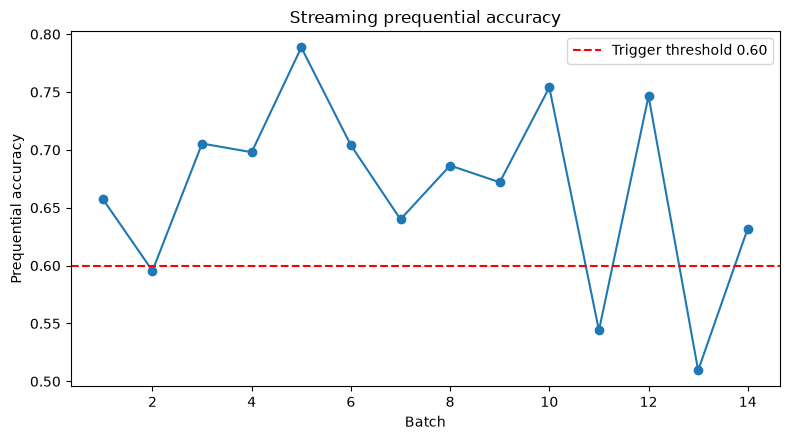

In [3]:
# On trigger, a fresh model is retrained on the most recent window (simulated here on the last 6000 stream rows before the end, for demonstration)
from sklearn.ensemble import RandomForestClassifier
if triggers:
    window=stream.iloc[-6000:]; Xw=scaler.transform(window[FEATURES]); yw=window[TARGET].values
    from sklearn.model_selection import train_test_split
    Xtr,Xte,ytr,yte=train_test_split(Xw, yw, test_size=0.25, random_state=42, stratify=yw)
    rm=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1); rm.fit(Xtr,ytr); print("Retrained RF on recent window, test accuracy:", round(accuracy_score(yte, rm.predict(Xte)),4))
else:
    print("No trigger fired in this stream (rolling accuracy stayed >=0.60). Retraining would not be triggered automatically under the stated rule, which is itself a result: do not force a retrain to claim one.")
if preq:
    plt.plot([b for b,_ in preq], [a for _,a in preq], marker="o"); plt.axhline(0.60, color="red", linestyle="--", label="Trigger threshold 0.60"); plt.xlabel("Batch"); plt.ylabel("Prequential accuracy"); plt.title("Streaming prequential accuracy"); plt.legend(); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: Prequential accuracy (predict before learning from each batch) is the honest streaming metric, because it never tests on data already used for training in that batch. A trigger rule must be fixed in advance (here: 2-batch rolling mean <0.60) so retraining is not chosen after seeing the results.")

INTERPRETATION: Prequential accuracy (predict before learning from each batch) is the honest streaming metric, because it never tests on data already used for training in that batch. A trigger rule must be fixed in advance (here: 2-batch rolling mean <0.60) so retraining is not chosen after seeing the results.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.